<div style="background:#eef3f8;padding:28px;border-left:6px solid #b7a4cf;color:#354052">
<h1 style="margin:0">Blender Is All You Need?</h1>
<p style="font-size:18px">S6E10 · Airline Satisfaction · An evidence-first ensemble laboratory</p>
<p>Public OOF libraries → input audit → diversity → controlled experiments → seven submission candidates.</p>
</div>

## Research brief

**Question:** How much useful signal can we extract from public prediction libraries, and which improvements survive stronger validation?

This notebook studies seven blend hypotheses, family contributions, model redundancy, and uncertainty. Results are computed from the attached inputs. It does not promise a leaderboard gain.

**Read the evidence at the correct level:** public-OOF meta-CV is a screening tool. A separate optional raw-data holdout tests a small independently trained ensemble. Neither makes downloaded OOF files fully independent.

**Author contribution:** the loading, audit, evaluation, plotting, and export pipeline here is newly written. Model predictions belong to the upstream authors credited below.

In [1]:
'''Reader contract
Each major section states a question, a method, and a limitation. Triple-quoted commentary cells
follow the CASMI notebook style; Markdown cells provide the reading structure.
All computations live in classes. Invocation cells only configure objects, run methods, and display
results.
The default run uses real attached data. It never substitutes synthetic competition observations.
Self-checks use small artificial fixtures solely to test implementation behavior.''';

## 1 · Sources, attribution, and reproducibility

Attach these two datasets for the primary panel:

- [megayak · S6E10 OOF library](https://www.kaggle.com/datasets/megayak/s6e10-oof-library): GBDT and RealMLP members, labels, IDs, and documented shared folds. RealMLP seed groups are averaged before stacking.
- [Chris Deotte · TFM OOF and test predictions](https://www.kaggle.com/datasets/cdeotte/s6e10-tfm-oof-and-test-predictions): foundation-model predictions and raw-feature XGBoost/RealMLP baselines. NPY row identity relies on the publisher's documented original train/test order.
- [Official competition files](https://www.kaggle.com/competitions/playground-series-s6e10/data): needed for official sample checks, feature slices, and independent holdout.

Optional supported extensions:

- [sachith7 · Stack OOF predictions](https://www.kaggle.com/datasets/sachith7/s6e10-stack-oof-predictions), paired `oof`/`test` arrays in NPZ files.
- [goodpjw2008 · Route-category stack](https://www.kaggle.com/code/goodpjw2008/s6e10-tabpfn-route-categories-lb-0-96160), `oof_members.csv` and `test_members.csv` with IDs. Attach one pinned version with this schema.

**Research references:** [Kratosyan's public-library stack](https://www.kaggle.com/code/kratosyan/s6e10-stacking-every-public-oof-library), [fold-averaging experiment](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/747182), [feature ladder](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/747358), [TFM comparison](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/746363).

Upstream dataset, notebook, and model licences remain applicable. Check them before redistribution. Local input SHA256 hashes preserve which exact files were used; download timestamps alone do not pin a version.

### Environment
Python ≥3.10; NumPy, pandas, SciPy, scikit-learn ≥1.4, seaborn ≥0.13, matplotlib, pyarrow, threadpoolctl, IPython. Kaggle normally provides these packages. No network downloads or automatic uploads occur inside this notebook.

Locally, place attached inputs under `inputs/<dataset-slug>/` and set `BLENDER_INPUT_ROOT=inputs`, `BLENDER_OUTPUT_ROOT=blender_results` before launching Jupyter.

**Kaggle input setup:** Competition CSV files alone are insufficient. Use **Add Input** to attach both public prediction datasets above, then **Run All**. The loader supports nested dataset directories and reports visible files when predictions are missing.


In [2]:
from pathlib import Path
from dataclasses import dataclass, asdict
from collections import Counter
import hashlib, json, platform, re, time, zipfile
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import minimize
from scipy.special import expit, logit
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, HTML

import os, importlib.metadata

In [3]:
@dataclass
class ResearchConfig:
    input_root: str = '/kaggle/input'
    output_root: str = '/kaggle/working/blender_lab'
    seeds: tuple = (137, 271)
    folds: int = 5
    max_fit_rows: int = 200000
    inner_rows: int = 40000
    c_grid: tuple = (0.01, 0.1, 1.0)
    compact_members: int = 8
    bootstrap_rows: int = 60000
    bootstrap_repeats: int = 100
    threads: int = 4
    allow_library_labels: bool = True
    enable_holdout: bool = False
    holdout_folds: int = 3
    holdout_rounds: int = 150
    seed: int = 42

In [4]:
class Presentation:
    COLORS = {'GBDT':'#8AB6C8', 'MLP':'#B7A4CF', 'TFM':'#D9ABAD', 'Mixed':'#A8C5B1'}

    @classmethod
    def setup(cls):
        sns.set_theme(style='whitegrid', context='notebook', palette=list(cls.COLORS.values()),
                      rc={'axes.spines.top':False, 'axes.spines.right':False,
                          'grid.color':'#E8E9EC','axes.labelcolor':'#354052',
                          'text.color':'#354052','figure.dpi':125, 'savefig.dpi':170})
        display(HTML('<style>.dataframe{font-size:12px} .dataframe th{background:#edf2f7;'
                     'color:#354052} .dataframe td{padding:7px} '
                     '.rendered_html h2{color:#43546b}</style>'))

    @staticmethod
    def table(frame, limit=25):
        display(frame.head(limit).style.format(precision=6, na_rep='—').hide(axis='index'))

    @staticmethod
    def note(text):
        display(Markdown(text))

    @staticmethod
    def finish(fig, title, path, subtitle=''):
        fig.suptitle(title, fontsize=16, fontweight='bold', x=0.02, ha='left')
        if subtitle:
            fig.text(0.02, 0.01, subtitle, fontsize=9, color='#596579', wrap=True)
        fig.tight_layout(rect=(0,0.065,1,0.93))
        fig.savefig(path, bbox_inches='tight')
        plt.show()
        plt.close(fig)

In [5]:
config = ResearchConfig(input_root=os.getenv('BLENDER_INPUT_ROOT', '/kaggle/input'),
                        output_root=os.getenv('BLENDER_OUTPUT_ROOT', '/kaggle/working/blender_lab'))
Presentation.setup()
Presentation.table(pd.DataFrame({'parameter':list(asdict(config)), 'value':[str(v) for v in asdict(config).values()]}))

parameter,value
input_root,/Users/flexonafft/Documents/Codex/2026-10-11/new-chat/work/inputs
output_root,/Users/flexonafft/Documents/Codex/2026-10-11/new-chat/outputs/research_run
seeds,"(137, 271)"
folds,5
max_fit_rows,200000
inner_rows,40000
c_grid,"(0.01, 0.1, 1.0)"
compact_members,8
bootstrap_rows,60000
bootstrap_repeats,100


## 2 · Context & methods

| Hypothesis | Experiment | Selection boundary |
|---|---|---|
| Simple averaging already captures most signal | Mean probabilities | No learned weights |
| Prediction scales differ across models | Training-reference ECDF rank blend | ECDF fitted on meta-training rows |
| Some models deserve more influence | Nonnegative convex blend | Log-loss weights fitted on meta-training rows |
| Logit combinations improve ranking | Logistic stack | `C` chosen on an inner split |
| A smaller panel retains the signal | Compact stack | Member selection inside each meta-training partition |
| TFM add distinct information | Stack excluding TFM; family ablations | Full protocol refitted after removal |
| Shrinking the learned stack improves robustness | 75% stack + 25% mean | Mixture fraction fixed before evaluation |

### Key assumptions

1. Downloaded OOF predictions were produced without fitting each row's target directly; this cannot be proved from prediction files alone.
2. Public libraries can share training labels, features, tuning decisions, and base models. Meta-CV does **not** eliminate those dependencies.
3. Test predictions often average fold models, while each base OOF row comes from one fold model. Improvement from seed diversity may shrink on test.
4. ECDF rank predictions use a distribution fitted on meta-training OOF, then applied to both validation and test. Distribution changes can affect this method.
5. The fit budget is explicit: at most 200,000 stratified rows per learned final/meta estimator and 40,000 for inner tuning and convex weights. Set `max_fit_rows=None` to use all rows for logistic fits. These are compute controls, not new data splits.
6. Candidate selection and bootstrap intervals are exploratory. The best tested result can be optimistic; intervals do not include upstream training or model-selection uncertainty.

**Protocol:** two meta split seeds × five folds by default. Compact selection and hyperparameter choice never inspect the corresponding meta-validation labels. Fixed-prediction paired bootstrap uses one preregistered stratified sample and the first meta seed. No weights are tuned using public scores.

In [6]:
'''Why the wording matters
This notebook calls the primary estimate public-OOF meta-CV, not fully nested CV. An outer meta fold
is excluded from fitting the stacker, but its labels may have contributed to upstream base models
that produced other rows.
The independent holdout section retrains a small separate ensemble entirely without holdout labels.
Its scores validate that experiment only, not the public OOF panel.
Convex weights minimize log loss as a smooth surrogate. Logistic regularization is chosen by inner
AUC. Both are evaluated by outer ROC AUC.''';

## 3 · Data: identity, validity, and lineage

**Question:** Are the prediction files safe to combine?

ID-keyed tables must match the complete reference population exactly. Array-only sources retain an explicit weaker identity status. Exact duplicates are removed using both OOF and test bytes; near-duplicates are only flagged. Seed grouping follows documented megayak model names.

If official files are absent, `allow_library_labels=True` allows the megayak label/ID mirror. The output manifest then states that the official sample was not checked. Set it to `False` to require official files.

In [7]:
class InputCatalog:
    URLS = {
        's6e10-oof-library':'https://www.kaggle.com/datasets/megayak/s6e10-oof-library',
        's6e10-tfm-oof-and-test-predictions':'https://www.kaggle.com/datasets/cdeotte/s6e10-tfm-oof-and-test-predictions',
        's6e10-stack-oof-predictions':'https://www.kaggle.com/datasets/sachith7/s6e10-stack-oof-predictions',
        's6e10-tabpfn-route-categories-lb-0-96160':'https://www.kaggle.com/code/goodpjw2008/s6e10-tabpfn-route-categories-lb-0-96160'}

    def __init__(self, config):
        self.config = config
        self.root = Path(config.input_root)
        self.out = Path(config.output_root)
        self.out.mkdir(parents=True, exist_ok=True)
        self.files = []
        self.rows, self.meta, self.audit = {}, [], []

    @staticmethod
    def sha(path):
        digest = hashlib.sha256()
        with open(path,'rb') as handle:
            for block in iter(lambda:handle.read(2**20), b''):
                digest.update(block)
        return digest.hexdigest()

    def directory(self, slug, required=False):
        markers = {
            'playground-series-s6e10': 'sample_submission.csv',
            's6e10-oof-library': 'oof_predictions.parquet',
            's6e10-tfm-oof-and-test-predictions': 'oof_*.npy',
            's6e10-stack-oof-predictions': '*.npz',
            's6e10-tabpfn-route-categories-lb-0-96160': 'oof_members.csv',
        }
        mounts = [p for p in self.root.rglob('*') if p.is_dir() and p.name == slug]
        if self.root.name == slug:
            mounts.append(self.root)
        matches = set()
        for mount in mounts:
            matches.update(p.parent for p in mount.rglob(markers[slug]) if p.is_file())
        # Competition and ID-keyed library schemas have distinctive filenames.
        if not matches and slug in ('playground-series-s6e10', 's6e10-oof-library'):
            matches.update(p.parent for p in self.root.rglob(markers[slug]) if p.is_file())
        if len(matches) > 1:
            raise ValueError(f'Ambiguous input {slug}: {sorted(map(str, matches))}. Keep one pinned version.')
        if not matches and required:
            raise FileNotFoundError(f'Attach {slug}; expected {markers[slug]} under {self.root}')
        return next(iter(matches)) if matches else None

    def record(self, path, source):
        self.files.append({'source':source, 'file':str(path.relative_to(self.root)),
                           'bytes':path.stat().st_size, 'sha256':self.sha(path),
                           'url':self.URLS.get(source, 'Competition input')})

    @staticmethod
    def align(frame, ids, column):
        if not frame['id'].is_unique or frame['id'].isna().any():
            raise ValueError('Duplicate or missing prediction IDs')
        if set(frame['id']) != set(ids):
            raise ValueError('Prediction IDs do not exactly match the reference')
        return frame.set_index('id').loc[ids, column].to_numpy(dtype=np.float32)

    def load_reference(self):
        directory = self.directory('playground-series-s6e10')
        if directory:
            self.train = pd.read_csv(directory/'train.csv')
            self.test = pd.read_csv(directory/'test.csv')
            self.sample = pd.read_csv(directory/'sample_submission.csv')
            self.reference = 'Official competition CSV files'
            self.official = True
            for name in ('train.csv','test.csv','sample_submission.csv'):
                self.record(directory/name,'playground-series-s6e10')
        elif self.config.allow_library_labels:
            directory = self.directory('s6e10-oof-library',required=True)
            self.train = pd.read_parquet(directory/'oof_predictions.parquet',
                                         columns=['id','satisfaction'])
            self.test = pd.read_parquet(directory/'test_predictions.parquet',columns=['id'])
            self.sample = self.test.assign(satisfaction=0.5)
            self.reference = 'Public megayak label/ID mirror; sample template reconstructed'
            self.official = False
        else:
            raise FileNotFoundError('Attach competition train/test/sample_submission CSV files.')
        if list(self.sample.columns)!=['id','satisfaction']:
            raise ValueError('Unexpected submission schema')
        for frame in (self.train, self.test, self.sample):
            if not frame.id.is_unique or frame.id.isna().any():
                raise ValueError('Reference IDs are missing or duplicated')
        if set(self.train.id)&set(self.test.id):
            raise ValueError('Train and test IDs overlap')
        if set(self.sample.id)!=set(self.test.id):
            raise ValueError('Sample IDs do not match test IDs')
        target = self.train.satisfaction
        if target.isna().any() or set(target.unique())!={0,1}:
            raise ValueError('Expected complete binary target encoded as 0/1')
        self.y = target.to_numpy(dtype=np.int8)
        self.train_ids = self.train.id.to_numpy()
        self.test_ids = self.test.id.to_numpy()
        self.sample_ids = self.sample.id.to_numpy()
        self.base_folds = np.full(len(self.y), -1)
        return self

    @staticmethod
    def family(name):
        value = name.lower()
        if any(token in value for token in ('lgb','xgb','xgboost','cat')): return 'GBDT'
        if any(token in value for token in ('realmlp','tabm','deepfm','mlp')): return 'MLP'
        if any(token in value for token in ('tabpfn','tabicl','tabfm','kumo','causilo','exaone','limix','mitra')): return 'TFM'
        return 'Mixed'

    def add(self, name, oof, test, source, folds, identity, components=None):
        oof, test = np.asarray(oof), np.asarray(test)
        reason = None
        if name in self.rows: raise ValueError(f'Duplicate member name: {name}')
        if oof.shape!=(len(self.y),) or test.shape!=(len(self.test_ids),):
            reason = 'Invalid array shape'
        elif not np.isfinite(oof).all() or not np.isfinite(test).all():
            reason = 'Non-finite values'
        elif min(oof.min(),test.min())<0 or max(oof.max(),test.max())>1:
            reason = 'Values outside [0, 1]'
        if reason:
            self.audit.append({'member':name,'status':'rejected','reason':reason})
            return
        oof,test = oof.astype(np.float32),test.astype(np.float32)
        fingerprint = hashlib.sha256(oof.tobytes()+test.tobytes()).hexdigest()
        duplicate = next((m['member'] for m in self.meta if m['fingerprint']==fingerprint),None)
        if duplicate:
            self.audit.append({'member':name,'status':'duplicate','reason':f'Exact copy of {duplicate}'})
            return
        self.rows[name] = (oof,test)
        self.meta.append({'member':name,'source':source,'family':self.family(name),
                          'fold_scheme':folds,'identity_check':identity,'fingerprint':fingerprint,
                          'components':components or [name]})
        self.audit.append({'member':name,'status':'accepted','reason':identity})

    def load(self):
        directory = self.directory('s6e10-oof-library')
        if directory:
            op,tp = directory/'oof_predictions.parquet',directory/'test_predictions.parquet'
            o,t = pd.read_parquet(op),pd.read_parquet(tp)
            if not np.array_equal(self.align(o,self.train_ids,'satisfaction'),self.y):
                raise ValueError('Library labels disagree with reference labels')
            self.base_folds = self.align(o,self.train_ids,'fold').astype(int)
            expected = np.zeros(len(self.y), dtype=int)
            for fold,(_,v) in enumerate(StratifiedKFold(5,shuffle=True,random_state=42).split(self.train_ids,self.y)):
                expected[v] = fold
            if not np.array_equal(expected,self.base_folds):
                raise ValueError('megayak folds disagree with documented SKFold(5, seed=42)')
            groups = {}
            for column in t.columns:
                if column=='id':continue
                key = re.sub(r'_s\d+$','',column) if column.startswith('realmlp') else column
                groups.setdefault(key,[]).append(column)
            for key,columns in groups.items():
                oo = np.mean([self.align(o,self.train_ids,c) for c in columns],axis=0)
                tt = np.mean([self.align(t,self.test_ids,c) for c in columns],axis=0)
                self.add('megayak__'+key,oo,tt,'s6e10-oof-library','5-fold seed 42',
                         'ID aligned; seed group averaged',columns)
            self.record(op,'s6e10-oof-library');self.record(tp,'s6e10-oof-library')
        directory = self.directory('s6e10-tfm-oof-and-test-predictions')
        if directory:
            # shortcut: NPY files have no IDs; replace with ID-keyed files when the publisher provides them.
            for path in sorted(directory.rglob('oof_*.npy')):
                test_path = path.with_name('test_'+path.name[4:])
                if not test_path.exists():raise FileNotFoundError(test_path)
                self.add('cdeotte__'+path.stem[4:],np.load(path,allow_pickle=False),
                         np.load(test_path,allow_pickle=False),'s6e10-tfm-oof-and-test-predictions',
                         '5-fold seed 42','Publisher-documented row order; IDs unavailable')
                self.record(path,'s6e10-tfm-oof-and-test-predictions')
                self.record(test_path,'s6e10-tfm-oof-and-test-predictions')
        directory = self.directory('s6e10-stack-oof-predictions')
        if directory:
            for path in sorted(directory.rglob('*.npz')):
                with np.load(path,allow_pickle=False) as arrays:
                    self.add('sachith7__'+path.stem, arrays['oof'],arrays['test'],
                             's6e10-stack-oof-predictions','10-fold if k10 in name; otherwise inspect upstream',
                             'Publisher row order; IDs unavailable')
                self.record(path,'s6e10-stack-oof-predictions')
        directory = self.directory('s6e10-tabpfn-route-categories-lb-0-96160')
        if directory:
            op,tp=directory/'oof_members.csv',directory/'test_members.csv'
            o,t=pd.read_csv(op),pd.read_csv(tp)
            columns=[c for c in t.columns if c!='id']
            if not set(columns).issubset(o.columns):raise ValueError('Member columns differ')
            for column in columns:
                self.add('goodpjw__'+column,self.align(o,self.train_ids,column),
                         self.align(t,self.test_ids,column),
                         's6e10-tabpfn-route-categories-lb-0-96160','Inspect pinned upstream version','ID aligned')
            self.record(op,'s6e10-tabpfn-route-categories-lb-0-96160')
            self.record(tp,'s6e10-tabpfn-route-categories-lb-0-96160')
        if len(self.rows) < 2:
            visible = sorted(str(p.relative_to(self.root)) for p in self.root.rglob('*') if p.is_file())
            rejected = [row for row in self.audit if row['status'] != 'accepted']
            raise ValueError(
                f'Loaded {len(self.rows)} unique valid OOF/test members. '
                'Competition train/test CSVs alone do not contain model predictions. '
                'In Kaggle, use Add Input to attach megayak/s6e10-oof-library and '
                'cdeotte/s6e10-tfm-oof-and-test-predictions, then Run All. '
                f'Input root: {self.root}. Visible files (first 40): {visible[:40]}. '
                f'Rejected or duplicate members: {rejected[:20]}'
            )
        self.metadata=pd.DataFrame(self.meta).set_index('member')
        self.names=list(self.rows)
        self.P=np.column_stack([self.rows[n][0] for n in self.names])
        self.T=np.column_stack([self.rows[n][1] for n in self.names])
        del self.rows
        self.metadata.to_csv(self.out/'member_registry.csv')
        pd.DataFrame(self.audit).to_csv(self.out/'input_audit.csv',index=False)
        (self.out/'input_provenance.json').write_text(json.dumps(self.files,indent=2))
        return self

In [8]:
inputs = InputCatalog(config).load_reference().load()
Presentation.note(f'**Reference:** {inputs.reference}. **Rows:** {len(inputs.y):,} train / {len(inputs.test_ids):,} test. **Positive share:** {inputs.y.mean():.3%}.')
Presentation.table(pd.DataFrame(inputs.audit), 40)
Presentation.table(inputs.metadata.reset_index().drop(columns=['fingerprint']), 30)

**Reference:** Public megayak label/ID mirror; sample template reconstructed. **Rows:** 699,635 train / 299,844 test. **Positive share:** 44.357%.

member,status,reason
megayak__lgb,accepted,ID aligned; seed group averaged
megayak__xgb,accepted,ID aligned; seed group averaged
megayak__cat,accepted,ID aligned; seed group averaged
megayak__realmlp,accepted,ID aligned; seed group averaged
megayak__realmlp_fa4,accepted,ID aligned; seed group averaged
megayak__realmlp_v4,accepted,ID aligned; seed group averaged
megayak__lgb_route,accepted,ID aligned; seed group averaged
megayak__lgb_ogteach,accepted,ID aligned; seed group averaged
megayak__realmlp_og,accepted,ID aligned; seed group averaged
megayak__realmlp_v4og,accepted,ID aligned; seed group averaged


member,source,family,fold_scheme,identity_check,components
megayak__lgb,s6e10-oof-library,GBDT,5-fold seed 42,ID aligned; seed group averaged,['lgb']
megayak__xgb,s6e10-oof-library,GBDT,5-fold seed 42,ID aligned; seed group averaged,['xgb']
megayak__cat,s6e10-oof-library,GBDT,5-fold seed 42,ID aligned; seed group averaged,['cat']
megayak__realmlp,s6e10-oof-library,MLP,5-fold seed 42,ID aligned; seed group averaged,"['realmlp_s42', 'realmlp_s7', 'realmlp_s123']"
megayak__realmlp_fa4,s6e10-oof-library,MLP,5-fold seed 42,ID aligned; seed group averaged,"['realmlp_fa4_s42', 'realmlp_fa4_s7', 'realmlp_fa4_s123']"
megayak__realmlp_v4,s6e10-oof-library,MLP,5-fold seed 42,ID aligned; seed group averaged,"['realmlp_v4_s42', 'realmlp_v4_s7', 'realmlp_v4_s123']"
megayak__lgb_route,s6e10-oof-library,GBDT,5-fold seed 42,ID aligned; seed group averaged,['lgb_route']
megayak__lgb_ogteach,s6e10-oof-library,GBDT,5-fold seed 42,ID aligned; seed group averaged,['lgb_ogteach']
megayak__realmlp_og,s6e10-oof-library,MLP,5-fold seed 42,ID aligned; seed group averaged,"['realmlp_og_s42', 'realmlp_og_s7']"
megayak__realmlp_v4og,s6e10-oof-library,MLP,5-fold seed 42,ID aligned; seed group averaged,"['realmlp_v4og_s42', 'realmlp_v4og_s7']"


In [9]:
'''Audit interpretation
A file passing shape and probability checks is not proof of leakage-free training. No automatic
inversion based on labels is performed. Publisher-documented NPY ordering remains an assumption,
recorded in the registry and each passport.
Optional loaders fail clearly on schema drift. Unknown arrays are not guessed or silently scanned
into the ensemble. Input hashes identify the exact attached files.''';

## 4 · Implementation checks

These artificial fixtures test ID alignment, invalid IDs, tied ranks, simplex weights, TFM exclusion, and unseen route handling. Their numbers are not competition results.

In [10]:
class BlendEstimator:
    def __init__(self,kind,config,metadata):
        self.kind,self.config,self.metadata=kind,config,metadata

    @staticmethod
    def bounded_indices(y, maximum, seed):
        indices=np.arange(len(y))
        if maximum and len(y)>maximum:
            indices,_=train_test_split(indices,train_size=maximum,stratify=y,random_state=seed)
        return indices

    @staticmethod
    def logits(P):
        return logit(np.clip(P,1e-6,1-1e-6)).astype(np.float64)

    def fit(self,P,y):
        self.columns=np.arange(P.shape[1])
        if self.kind=='without_tfm':
            self.columns=np.flatnonzero(self.metadata.family.to_numpy()!='TFM')
            if not len(self.columns):raise ValueError('No non-TFM members available')
        if self.kind=='compact':
            sample=self.bounded_indices(y,self.config.inner_rows,self.config.seed)
            scores=np.array([roc_auc_score(y[sample],P[sample,j]) for j in self.columns])
            order=np.argsort(-scores,kind='stable')
            chosen=[];groups=Counter()
            for j in order:
                group=(self.metadata.iloc[j]['source'],self.metadata.iloc[j]['family'])
                if groups[group]<2:
                    chosen.append(int(j));groups[group]+=1
                if len(chosen)>=self.config.compact_members:break
            self.columns=np.array(chosen)
        X=P[:,self.columns]
        if self.kind=='rank':
            self.sorted_columns=[np.sort(X[:,j]) for j in range(X.shape[1])]
            return self
        if self.kind=='mean':return self
        sample=self.bounded_indices(y,self.config.max_fit_rows,self.config.seed)
        self.fit_rows=len(sample)
        X,labels=X[sample],y[sample]
        if self.kind=='weighted':
            small=self.bounded_indices(labels,self.config.inner_rows,self.config.seed)
            A,target=X[small].astype(float),labels[small]
            def objective(weights):
                pred=np.clip(A@weights,1e-7,1-1e-7)
                loss=-np.mean(target*np.log(pred)+(1-target)*np.log1p(-pred))
                grad=A.T@((pred-target)/(pred*(1-pred)))/len(target)
                return loss,grad
            result=minimize(objective,np.full(A.shape[1],1/A.shape[1]),jac=True,
                            method='SLSQP',bounds=[(0,1)]*A.shape[1],
                            constraints={'type':'eq','fun':lambda w:w.sum()-1,
                                         'jac':lambda w:np.ones_like(w)},
                            options={'maxiter':250,'ftol':1e-9})
            if not result.success:raise RuntimeError(f'Weight fit failed: {result.message}')
            self.weights=np.clip(result.x,0,1);self.weights/=self.weights.sum()
            return self
        inner=self.bounded_indices(labels,self.config.inner_rows,self.config.seed)
        train,valid=train_test_split(inner,test_size=0.25,stratify=labels[inner],random_state=self.config.seed)
        Z=self.logits(X)
        best=None
        for C in self.config.c_grid:
            model=self.fit_logistic(Z[train],labels[train],C)
            score=roc_auc_score(labels[valid],model.predict_proba(Z[valid])[:,1])
            if best is None or score>best[0]:best=(score,C)
        self.C=best[1]
        self.model=self.fit_logistic(Z,labels,self.C)
        return self

    @staticmethod
    def fit_logistic(Z,y,C):
        with warnings.catch_warnings():
            warnings.simplefilter('error',ConvergenceWarning)
            return LogisticRegression(C=C,max_iter=2000,tol=1e-6,solver='lbfgs').fit(Z,y)

    def predict(self,P):
        X=P[:,self.columns]
        if self.kind=='mean':return X.mean(axis=1,dtype=np.float64)
        if self.kind=='rank':
            pred=np.zeros(len(X),dtype=float)
            for j,reference in enumerate(self.sorted_columns):
                left=np.searchsorted(reference,X[:,j],side='left')
                right=np.searchsorted(reference,X[:,j],side='right')
                pred+=(left+right+1)/(2*(len(reference)+1))
            return pred/X.shape[1]
        if self.kind=='weighted':return X@self.weights
        pred=self.model.predict_proba(self.logits(X))[:,1]
        return 0.75*pred+0.25*X.mean(axis=1) if self.kind=='conservative' else pred

    def passport(self,names):
        result={'kind':self.kind,'members':[names[j] for j in self.columns],
                'fit_rows':getattr(self,'fit_rows',None)}
        if hasattr(self,'weights'):result['weights']=self.weights.tolist()
        if hasattr(self,'model'):
            result.update(C=self.C,coefficients=self.model.coef_[0].tolist(),
                          intercept=float(self.model.intercept_[0]))
        if self.kind=='conservative':result['stack_fraction']=0.75
        return result

In [11]:
class RouteFeatures:
    def fit(self,X):
        if 'Flight Distance' not in X:raise ValueError('Flight Distance feature is missing')
        numeric=[c for c in X.select_dtypes(include='number').columns if c!='Flight Distance']
        self.profile=X.groupby('Flight Distance')[numeric].mean()
        self.counts=X['Flight Distance'].value_counts()
        self.medians=X[numeric].median()
        self.numeric=numeric
        return self

    def transform(self,X,route=True):
        result=X.copy()
        if route:
            distance=X['Flight Distance']
            result['route_count']=distance.map(self.counts).fillna(0).astype(float)
            for column in self.numeric:
                mean=distance.map(self.profile[column]).fillna(self.medians[column])
                result['route_mean__'+column]=mean
                result['route_residual__'+column]=X[column]-mean
        return result

In [12]:
class ExperimentRunner:
    KINDS=('mean','rank','weighted','logit_stack','compact','without_tfm','conservative')

    def __init__(self,config,inputs):
        self.config,self.inputs=config,inputs
        self.predictions,self.folds,self.passports={},{},{}
        self.records=[]
        self.out=inputs.out

    def run(self):
        P,y=self.inputs.P,self.inputs.y
        with threadpool_limits(limits=self.config.threads):
            for seed in self.config.seeds:
                split=list(StratifiedKFold(self.config.folds,shuffle=True,random_state=seed).split(P,y))
                for kind in self.KINDS:
                    start=time.time();pred=np.full(len(y),np.nan);scores=[]
                    for fold,(train,valid) in enumerate(split):
                        estimator=BlendEstimator(kind,self.config,self.inputs.metadata).fit(P[train],y[train])
                        pred[valid]=estimator.predict(P[valid])
                        score=roc_auc_score(y[valid],pred[valid]);scores.append(score)
                        self.records.append({'variant':kind,'seed':seed,'fold':fold,'auc':score,
                                             'fit_rows':getattr(estimator,'fit_rows',len(train)),
                                             'members':len(estimator.columns)})
                    if not np.isfinite(pred).all():raise ValueError('Incomplete meta predictions')
                    self.predictions[(kind,seed)]=pred.astype(np.float32)
                    print(f'{kind:14s} | seed {seed} | meta-CV AUC {roc_auc_score(y,pred):.6f} | {time.time()-start:.1f}s')
            self.final={}
            for kind in self.KINDS:
                estimator=BlendEstimator(kind,self.config,self.inputs.metadata).fit(P,y)
                self.final[kind]=estimator.predict(self.inputs.T)
                self.passports[kind]=estimator.passport(self.inputs.names)
        self.fold_table=pd.DataFrame(self.records)
        self.fold_table.to_csv(self.out/'meta_fold_scores.csv',index=False)
        self.summary=pd.DataFrame([
            {'variant':kind,'mean_meta_auc':np.mean([roc_auc_score(y,self.predictions[(kind,s)]) for s in self.config.seeds]),
             'seed_auc_sd':np.std([roc_auc_score(y,self.predictions[(kind,s)]) for s in self.config.seeds]),
             'delta_vs_mean':np.mean([roc_auc_score(y,self.predictions[(kind,s)])-
                                     roc_auc_score(y,self.predictions[('mean',s)]) for s in self.config.seeds]),
             'final_members':len(self.passports[kind]['members'])}
            for kind in self.KINDS]).sort_values('mean_meta_auc',ascending=False)
        self.summary.to_csv(self.out/'experiment_summary.csv',index=False)
        return self

    def bootstrap(self):
        y=self.inputs.y
        index=BlendEstimator.bounded_indices(y,self.config.bootstrap_rows,812)
        labels=y[index];positive=np.flatnonzero(labels==1);negative=np.flatnonzero(labels==0)
        rng=np.random.default_rng(812)
        seed=self.config.seeds[0]
        base=self.predictions[('mean',seed)][index]
        draws=[]
        for _ in range(self.config.bootstrap_repeats):
            draws.append(np.r_[rng.choice(positive,len(positive),replace=True),
                               rng.choice(negative,len(negative),replace=True)])
        rows=[]
        for kind in self.KINDS:
            candidate=self.predictions[(kind,seed)][index]
            deltas=np.array([roc_auc_score(labels[d],candidate[d])-roc_auc_score(labels[d],base[d]) for d in draws])
            rows.append({'variant':kind,'sample_delta':roc_auc_score(labels,candidate)-roc_auc_score(labels,base),
                         'lower_95':np.quantile(deltas,.025),'upper_95':np.quantile(deltas,.975),
                         'rows':len(index),'resamples':len(draws),'meta_seed':seed})
        self.uncertainty=pd.DataFrame(rows)
        self.uncertainty.to_csv(self.out/'paired_bootstrap.csv',index=False)
        return self

    def ablate(self):
        P,y=self.inputs.P,self.inputs.y
        seed=self.config.seeds[0]
        splits=list(StratifiedKFold(self.config.folds,shuffle=True,random_state=seed).split(P,y))
        reference=self.predictions[('logit_stack',seed)]
        rows=[]
        with threadpool_limits(limits=self.config.threads):
            for family in self.inputs.metadata.family.unique():
                columns=np.flatnonzero(self.inputs.metadata.family.to_numpy()!=family)
                if not len(columns):continue
                pred=np.zeros(len(y))
                meta=self.inputs.metadata.iloc[columns]
                for train,valid in splits:
                    model=BlendEstimator('logit_stack',self.config,meta).fit(P[train][:,columns],y[train])
                    pred[valid]=model.predict(P[valid][:,columns])
                delta=roc_auc_score(y,reference)-roc_auc_score(y,pred)
                positive=sum(roc_auc_score(y[v],reference[v])>roc_auc_score(y[v],pred[v]) for _,v in splits)
                rows.append({'family':family,'removed_members':P.shape[1]-len(columns),
                             'contribution_auc':delta,'folds_positive':positive,'folds':len(splits)})
        self.ablations=pd.DataFrame(rows)
        self.ablations.to_csv(self.out/'family_ablations.csv',index=False)
        return self

In [13]:
class NotebookChecks:
    @staticmethod
    def run():
        rng=np.random.default_rng(19);y=np.tile([0,1],120)
        P=expit(rng.normal(size=(len(y),4))+.8*y[:,None]).astype(np.float32)
        metadata=pd.DataFrame({'family':['GBDT','MLP','TFM','GBDT'],'source':['a','b','c','d']})
        config=ResearchConfig(max_fit_rows=150,inner_rows=100,c_grid=(.1,),compact_members=3)
        for kind in ExperimentRunner.KINDS:
            estimator=BlendEstimator(kind,config,metadata).fit(P,y)
            pred=estimator.predict(P[:11])
            assert pred.shape==(11,) and np.isfinite(pred).all() and pred.min()>=0 and pred.max()<=1
            if kind=='weighted':assert abs(estimator.weights.sum()-1)<1e-8 and estimator.weights.min()>=0
            if kind=='without_tfm':assert not any(metadata.iloc[estimator.columns].family=='TFM')
        rank=BlendEstimator('rank',config,metadata).fit(np.array([[.2]*4,[.5]*4,[.5]*4,[.8]*4]),np.array([0,0,1,1]))
        assert np.allclose(rank.predict(np.array([[.5]*4])),.5)
        frame=pd.DataFrame({'id':[3,1,2],'prediction':[.3,.1,.2]})
        assert np.allclose(InputCatalog.align(frame,[1,2,3],'prediction'),[.1,.2,.3])
        try:InputCatalog.align(frame,[1,2,4],'prediction')
        except ValueError:pass
        else:raise AssertionError('Missing IDs must fail')
        source=pd.DataFrame({'Flight Distance':[10,10,20],'Age':[20.,40.,30.]})
        builder=RouteFeatures().fit(source)
        unseen=builder.transform(pd.DataFrame({'Flight Distance':[99],'Age':[50.]}))
        assert unseen.route_count.iloc[0]==0 and unseen.route_mean__Age.iloc[0]==30
        print('Self-checks passed: seven estimators, tied ECDF ranks, ID alignment, missing-ID rejection, unseen route fallback.')

In [14]:
NotebookChecks.run()

Self-checks passed: seven estimators, tied ECDF ranks, ID alignment, missing-ID rejection, unseen route fallback.


## 5 · Results: model strength and diversity

**Question:** Did we collect independent signal or many copies of the same predictions?

The first chart uses a focused AUC axis with points rather than zero-truncated bars. The heatmap uses a stratified sample, stable family colors, and a zero-anchored rank-distance scale (1 − Spearman correlation). Correlation is diagnostic; marginal held-out improvement decides whether a member is useful.

In [15]:
class ResearchPlots:
    def __init__(self,config,inputs):
        self.config,self.inputs=config,inputs
        self.out=inputs.out/'figures';self.out.mkdir(exist_ok=True)

    def model_map(self):
        data=self.inputs
        self.singles=data.metadata.reset_index()[['member','family','source']]
        self.singles['oof_auc']=[roc_auc_score(data.y,data.P[:,j]) for j in range(data.P.shape[1])]
        self.singles=self.singles.sort_values('oof_auc',ascending=False)
        self.singles.to_csv(data.out/'single_member_scores.csv',index=False)
        fig,ax=plt.subplots(figsize=(11,max(5,min(14,len(self.singles)*.3))))
        sns.scatterplot(data=self.singles.head(35),x='oof_auc',y='member',hue='family',
                        style='family',palette=Presentation.COLORS,s=75,ax=ax)
        ax.set(xlabel='OOF ROC AUC · focused score axis',ylabel='')
        Presentation.finish(fig,'Individual strength is only the starting point',self.out/'single_models.png',
                            'Base OOF results inherit upstream feature selection and early stopping.')
        indices=BlendEstimator.bounded_indices(data.y,min(40000,len(data.y)),421)
        self.correlation=pd.DataFrame(data.P[indices],columns=data.names).corr(method='spearman')
        ordered=data.metadata.sort_values(['family','source']).index.tolist()[:35]
        fig,ax=plt.subplots(figsize=(12,10))
        distance = 1 - self.correlation.loc[ordered,ordered]
        sns.heatmap(distance,cmap=sns.light_palette('#779AB3',as_cmap=True),
                    vmin=0,vmax=max(float(distance.max().max()),1e-6),square=True,ax=ax,
                    cbar_kws={'label':'Rank distance · 1 − Spearman correlation'})
        ax.set_xticklabels(ax.get_xticklabels(),rotation=60,ha='right')
        Presentation.finish(fig,'How much diversity did we actually collect?',self.out/'correlation.png',
                            f'Stratified sample: {len(indices):,} rows. Distance 0 = identical ranks; larger values = more disagreement. At most 35 members shown.')
        near=[]
        for i,name in enumerate(data.names):
            for j in range(i):
                value=self.correlation.iloc[i,j]
                if value>=.9999:near.append({'member_a':name,'member_b':data.names[j],'rank_correlation':value})
        pd.DataFrame(near,columns=['member_a','member_b','rank_correlation']).to_csv(data.out/'near_duplicates.csv',index=False)
        Presentation.table(self.singles,15)
        Presentation.note(f'**Observed:** {len(data.names)} accepted members, '
                          f'{data.metadata.family.nunique()} families, {len(near)} near-duplicate pairs '
                          'on the diagnostic sample. Near-duplicates are flagged, not automatically removed.')

    def experiments(self,runner):
        fig,ax=plt.subplots(figsize=(10,5))
        order=runner.summary.variant.tolist()
        sns.stripplot(data=runner.fold_table,x='auc',y='variant',order=order,color='#8AB6C8',
                      jitter=.15,size=6,alpha=.7,ax=ax)
        sns.pointplot(data=runner.summary,x='mean_meta_auc',y='variant',order=order,
                      color='#5C6687',linestyles='none',markers='D',errorbar=None,ax=ax)
        ax.set(xlabel='Meta-CV ROC AUC · dots are individual folds; diamonds are mean pooled seed AUC',ylabel='')
        Presentation.finish(fig,'Seven submission hypotheses, one evaluation protocol',self.out/'variants.png',
                            'Fold spread is descriptive; it is not a confidence interval. Public OOF meta-CV is not independent base-model validation.')
        fig,ax=plt.subplots(figsize=(10,5))
        uncertainty=runner.uncertainty.set_index('variant').loc[order].reset_index()
        sns.scatterplot(data=uncertainty,x='sample_delta',y='variant',color='#B7A4CF',s=85,ax=ax)
        for i,row in uncertainty.iterrows():
            ax.plot([row.lower_95,row.upper_95],[i,i],color='#7786A1',lw=2)
        ax.axvline(0,color='#596579',lw=1,ls='--')
        ax.set(xlabel='AUC difference versus mean · fixed stratified sample',ylabel='')
        Presentation.finish(fig,'Does the improvement survive paired resampling?',self.out/'uncertainty.png',
                            f'95% percentile paired bootstrap intervals; {len(uncertainty)} candidates, '
                            f'{self.config.bootstrap_repeats} resamples. Conditional on fixed predictions; no selection or training uncertainty.')
        fig,ax=plt.subplots(figsize=(9,4))
        sns.scatterplot(data=runner.summary,x='final_members',y='mean_meta_auc',
                        color='#A8C5B1',s=90,ax=ax)
        for _,row in runner.summary.iterrows():
            offset = 20 if row.variant=='logit_stack' else 6
            ax.annotate(row.variant,(row.final_members,row.mean_meta_auc),xytext=(8,offset),
                        textcoords='offset points',fontsize=9,
                        arrowprops={'arrowstyle':'-','color':'#B9C2CE','lw':.7})
        ax.set_xlim(max(0,runner.summary.final_members.min()-1),runner.summary.final_members.max()+3)
        ax.set(xlabel='Members in the final fitted variant',ylabel='Mean pooled meta-CV AUC')
        Presentation.finish(fig,'How much complexity buys additional score?',self.out/'complexity.png',
                            'Different blending methods are shown; this is not a controlled learning curve.')

    def ablations(self,runner):
        fig,ax=plt.subplots(figsize=(9,4))
        sns.barplot(data=runner.ablations,x='contribution_auc',y='family',hue='family',
                    palette=Presentation.COLORS,legend=False,ax=ax)
        ax.axvline(0,color='#596579',lw=1)
        ax.set(xlabel='Full stack AUC minus refitted stack without this family',ylabel='')
        Presentation.finish(fig,'Which families still contribute?',self.out/'ablations.png',
                            'Contributions overlap and are not additive. Regularization is retuned inside each training partition.')
        Presentation.table(runner.ablations)

    def shift(self,runner):
        seed=self.config.seeds[0]
        index=BlendEstimator.bounded_indices(self.inputs.y,min(30000,len(self.inputs.y)),98)
        oof=runner.predictions[('logit_stack',seed)][index]
        rng=np.random.default_rng(98)
        test=runner.final['logit_stack'][rng.choice(len(self.inputs.test_ids),min(30000,len(self.inputs.test_ids)),replace=False)]
        plot=pd.DataFrame({'prediction':np.r_[oof,test],
                           'population':['meta OOF']*len(oof)+['test']*len(test)})
        fig,ax=plt.subplots(figsize=(10,4))
        sns.histplot(data=plot,x='prediction',hue='population',bins=35,stat='density',
                     common_norm=False,element='step',palette=['#8AB6C8','#D9ABAD'],alpha=.3,ax=ax)
        Presentation.finish(fig,'OOF and test predictions: inspect the mismatch',self.out/'shift.png',
                            'Different averaging, training partitions, and population mix can all affect these distributions; this is not proof of shift.')

    def segments(self,runner):
        raw=self.inputs.train
        if 'Flight Distance' not in raw:
            Presentation.note('**Segment analysis unavailable:** the public label mirror contains no raw features. Attach official competition CSVs to enable it.')
            return
        distance=raw['Flight Distance'];counts=distance.map(distance.value_counts(dropna=False))
        segments={'distance_frequency':pd.cut(counts,bins=[0,10,50,200,np.inf],labels=['≤10','11–50','51–200','>200'])}
        for column in ('Class','Type of Travel','Customer Type'):
            if column in raw:segments[column]=raw[column].fillna('Missing').astype(str)
        rows=[];seed=self.config.seeds[0];y=self.inputs.y
        for feature,values in segments.items():
            for group in pd.Series(values).dropna().unique():
                index=np.flatnonzero(np.asarray(values==group))
                if len(index)<200 or min(np.sum(y[index]==0),np.sum(y[index]==1))<20:continue
                mean=roc_auc_score(y[index],runner.predictions[('mean',seed)][index])
                stack=roc_auc_score(y[index],runner.predictions[('logit_stack',seed)][index])
                rows.append({'feature':feature,'segment':str(group),'rows':len(index),
                             'positives':int(y[index].sum()),'mean_auc':mean,'stack_auc':stack,'delta':stack-mean})
        result=pd.DataFrame(rows);result.to_csv(self.inputs.out/'segment_diagnostics.csv',index=False)
        Presentation.table(result)
        if len(result):
            result['label']=result.feature+' · '+result.segment
            fig,ax=plt.subplots(figsize=(10,max(4,.4*len(result))))
            sns.scatterplot(data=result,x='delta',y='label',color='#B7A4CF',s=65,ax=ax)
            ax.axvline(0,color='#596579',ls='--');ax.set(xlabel='Within-segment AUC gain',ylabel='')
            Presentation.finish(fig,'Where do the models disagree usefully?',self.out/'segments.png',
                                'Exploratory slices; between-segment ranking is excluded. Do not tune gates on these results without a new validation layer.')

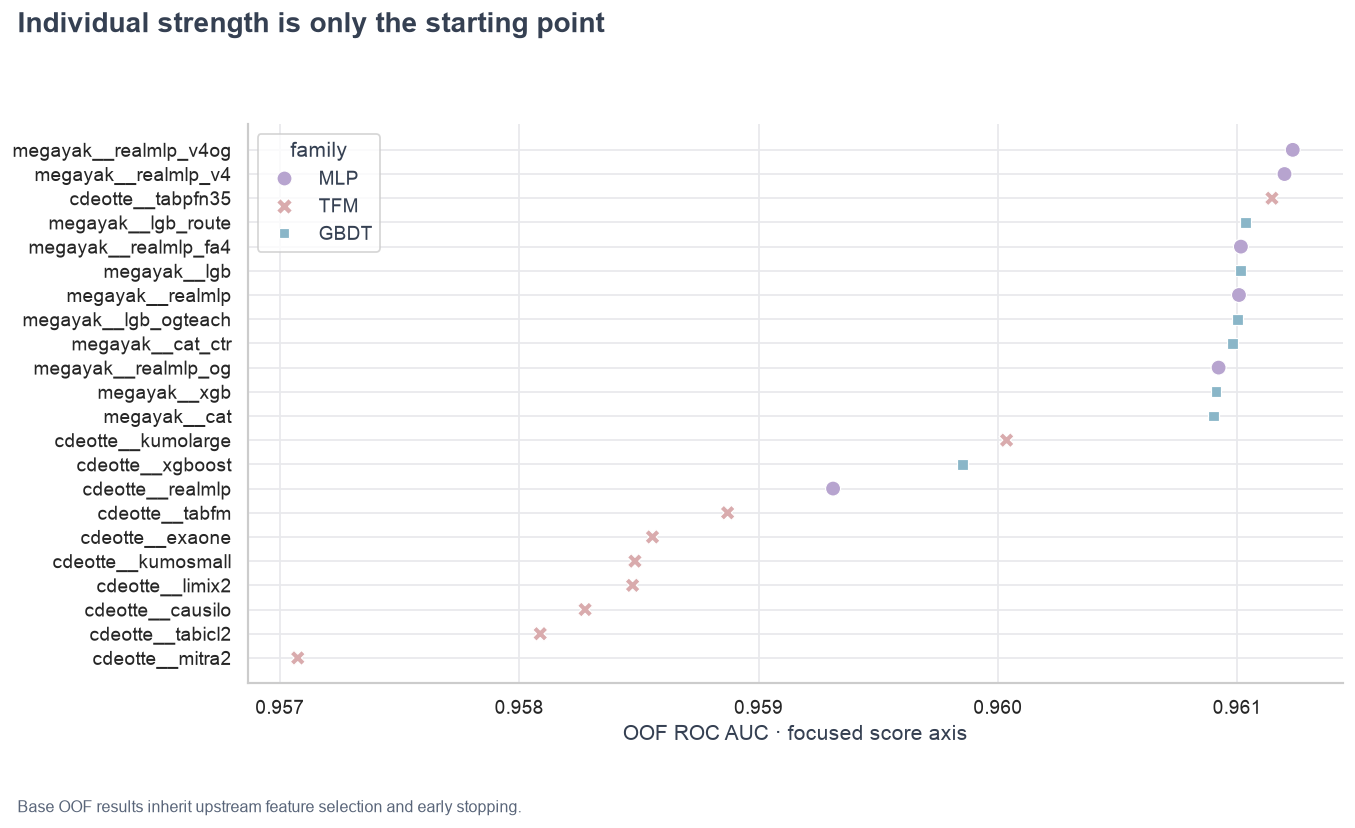

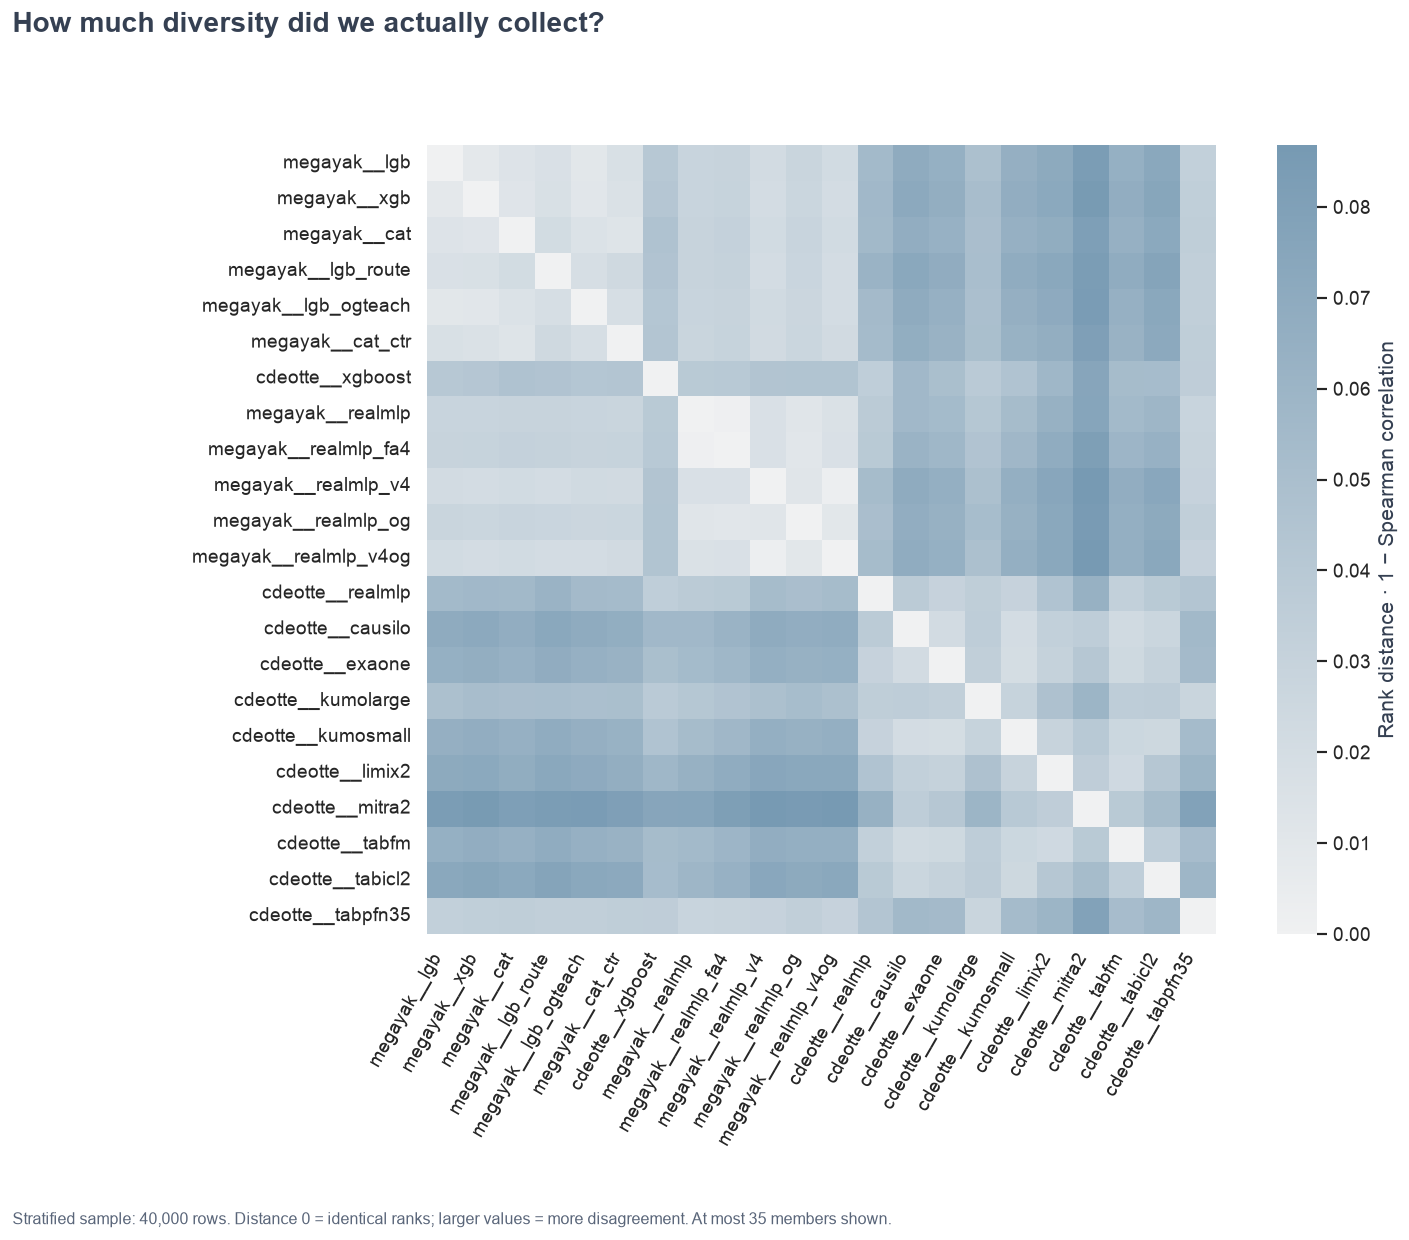

member,family,source,oof_auc
megayak__realmlp_v4og,MLP,s6e10-oof-library,0.961232
megayak__realmlp_v4,MLP,s6e10-oof-library,0.961198
cdeotte__tabpfn35,TFM,s6e10-tfm-oof-and-test-predictions,0.961145
megayak__lgb_route,GBDT,s6e10-oof-library,0.961035
megayak__realmlp_fa4,MLP,s6e10-oof-library,0.961015
megayak__lgb,GBDT,s6e10-oof-library,0.961014
megayak__realmlp,MLP,s6e10-oof-library,0.961007
megayak__lgb_ogteach,GBDT,s6e10-oof-library,0.961000
megayak__cat_ctr,GBDT,s6e10-oof-library,0.960980
megayak__realmlp_og,MLP,s6e10-oof-library,0.960922


**Observed:** 22 accepted members, 3 families, 0 near-duplicate pairs on the diagnostic sample. Near-duplicates are flagged, not automatically removed.

In [16]:
plots = ResearchPlots(config, inputs)
plots.model_map()

In [17]:
'''Reading the diversity map
A weaker single model can help if it corrects errors of the current ensemble. Conversely, a strong
highly correlated member may contribute almost nothing.
Near-identical predictions are not automatically dropped because tiny differences can still affect
AUC. Exact copies receive no extra vote. Grouped seed members also prevent a model with more
published seeds from getting more weight in the mean baseline.''';

## 6 · Controlled ensemble experiments

**Question:** Which mixing method improves over the same probability-mean control?

Seven fixed hypotheses share the same meta splits. Learned variants fit only on training rows. AUC is calculated from complete meta-validation predictions for each seed, then averaged across seeds. This is different from averaging seed predictions, which would add another ensemble layer.

A convergence warning or failed constrained optimization stops the run rather than silently exporting questionable weights.

In [18]:
runner = ExperimentRunner(config, inputs).run()
Presentation.table(runner.summary)

mean           | seed 137 | meta-CV AUC 0.961400 | 0.3s


rank           | seed 137 | meta-CV AUC 0.961144 | 4.2s


weighted       | seed 137 | meta-CV AUC 0.961692 | 1.2s


logit_stack    | seed 137 | meta-CV AUC 0.961811 | 3.8s


compact        | seed 137 | meta-CV AUC 0.961667 | 2.8s


...

logit_stack    | seed 271 | meta-CV AUC 0.961811 | 4.8s


compact        | seed 271 | meta-CV AUC 0.961678 | 2.8s


without_tfm    | seed 271 | meta-CV AUC 0.961551 | 3.4s


conservative   | seed 271 | meta-CV AUC 0.961800 | 4.9s


variant,mean_meta_auc,seed_auc_sd,delta_vs_mean,final_members
logit_stack,0.961811,0.000000,0.000410,22
conservative,0.961796,0.000003,0.000396,22
weighted,0.961677,0.000015,0.000277,22
compact,0.961673,0.000006,0.000272,8
without_tfm,0.961550,0.000002,0.000149,13
mean,0.961400,0.000000,0.000000,22
rank,0.961144,0.000000,-0.000257,22


### 6.1 · Paired uncertainty

**Question:** Is the observed difference larger than fixed-prediction sampling variation?

The percentile intervals use stratified paired bootstrap: each candidate and the mean control are evaluated on exactly the same resampled rows. The reported interval refers to the fixed diagnostic sample, not all train rows. It excludes training variability, shared base-fold dependence, upstream tuning, and selection of the best candidate. It is not a prediction interval for public LB.

variant,sample_delta,lower_95,upper_95,rows,resamples,meta_seed
mean,0.000000,0.000000,0.000000,60000,100,137
rank,-0.000207,-0.000310,-0.000101,60000,100,137
weighted,0.000186,-0.000003,0.000353,60000,100,137
logit_stack,0.000308,0.000045,0.000566,60000,100,137
compact,0.000176,-0.000094,0.000431,60000,100,137
without_tfm,0.000029,-0.000133,0.000243,60000,100,137
conservative,0.000306,0.000095,0.000495,60000,100,137


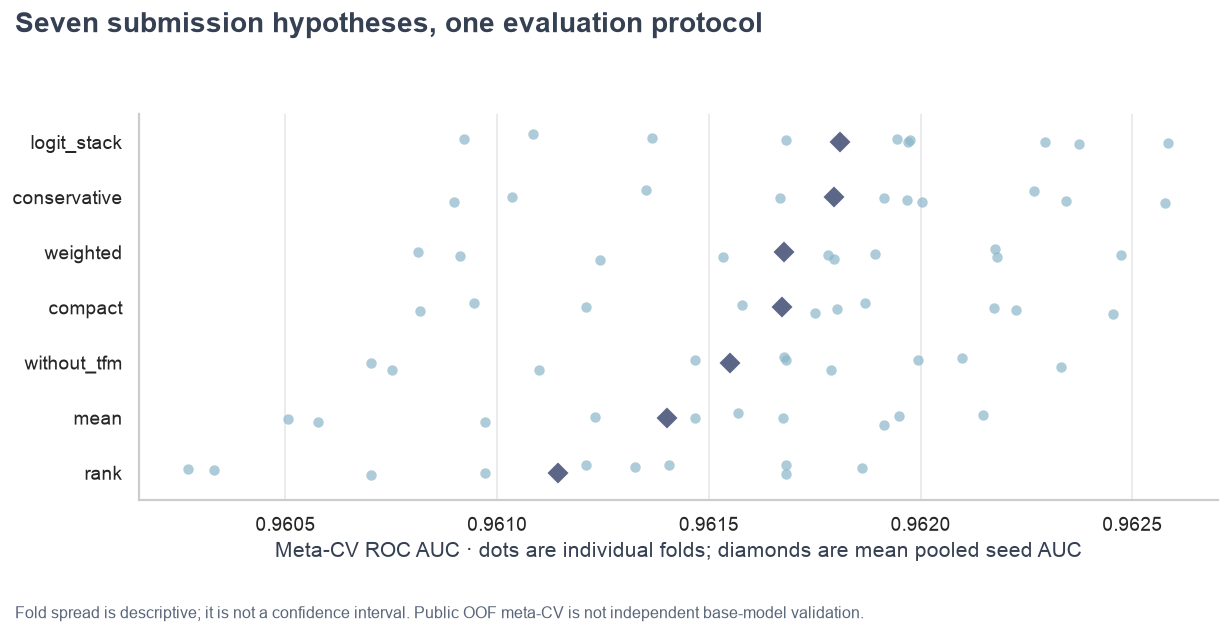

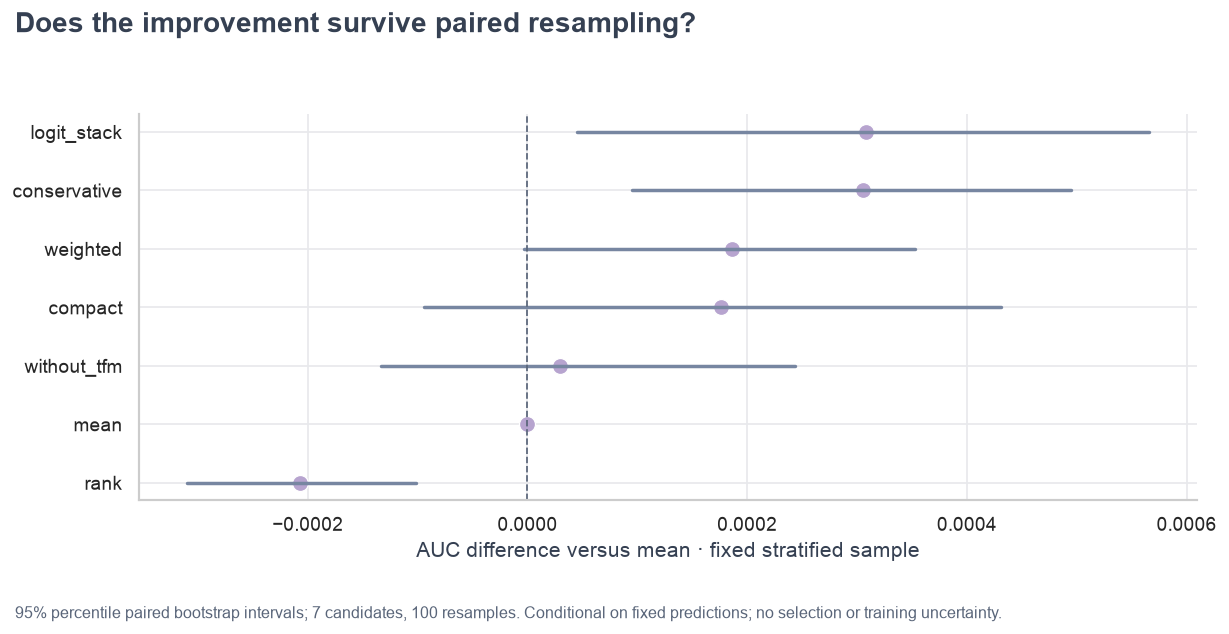

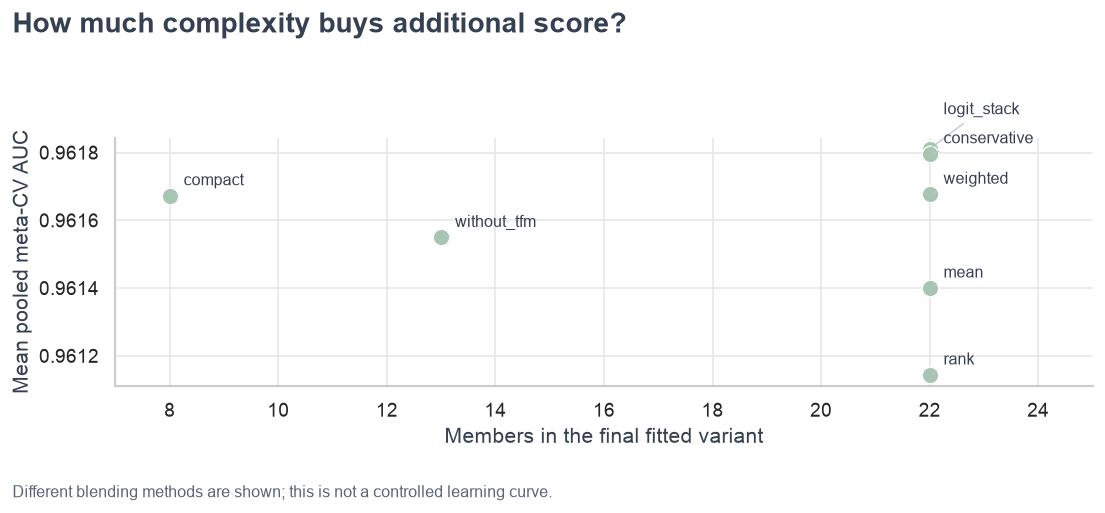

In [19]:
runner.bootstrap()
Presentation.table(runner.uncertainty)
plots.experiments(runner)

### 6.2 · Leave-one-family-out ablations

**Question:** What useful information disappears when a family is removed?

Each reduced stack is refitted and its regularization retuned inside training partitions. Positive contribution means the full stack performs better. Contributions overlap: do not sum the bars or interpret them as causal attribution.

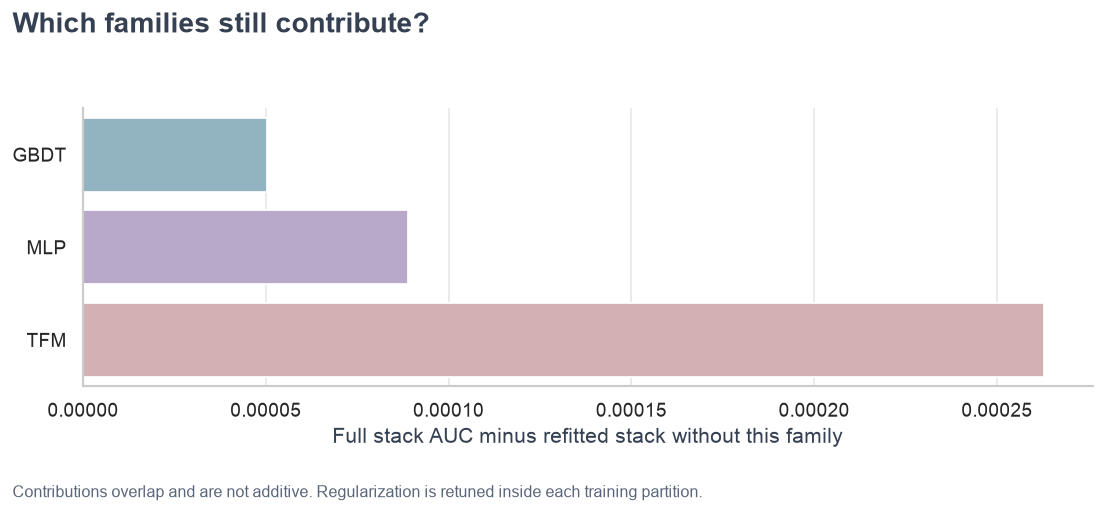

family,removed_members,contribution_auc,folds_positive,folds
GBDT,7,0.000050,5,5
MLP,6,0.000089,5,5
TFM,9,0.000263,5,5


In [20]:
runner.ablate()
plots.ablations(runner)

## 7 · Transfer diagnostics

**Question:** Where might OOF improvements fail to transfer?

Compare OOF and test distributions, then inspect available raw-feature segments. Histogram differences can reflect fold averaging and population mix as well as distribution shift. Segment AUC ignores cross-segment ordering, so it cannot replace overall AUC.

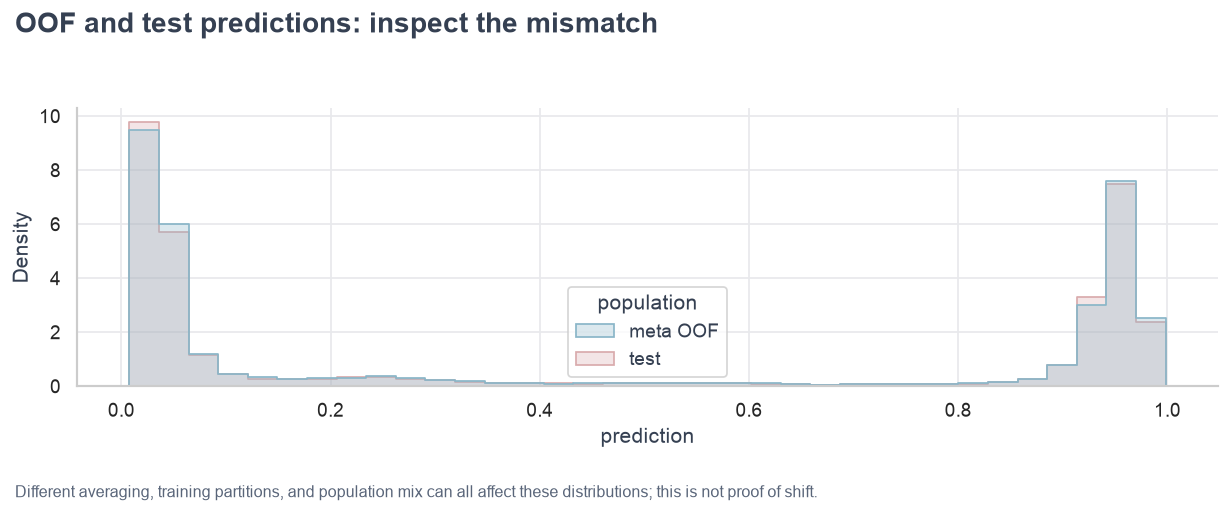

**Segment analysis unavailable:** the public label mirror contains no raw features. Attach official competition CSVs to enable it.

In [21]:
plots.shift(runner)
plots.segments(runner)

In [22]:
'''Feature hypotheses for the next modeling round
Flight Distance can carry repeated-value information. Route frequencies, mean profiles, residuals,
and carefully cross-fitted target encodings deserve separate ablations.
Original-data lookups and original-only teachers are distinct from concatenating original rows.
Their incremental contribution must be evaluated against the frozen stack, not only a single
baseline.
Do not build passenger-specific gates from these diagnostic slices and evaluate them on the same
rows. Add another selection boundary or a new untouched holdout.''';

## 8 · Optional independent holdout

**Question:** Does an ensemble gain survive test-like fold averaging on genuinely excluded labels?

Enable with `config.enable_holdout = True` **before this section** and attach official raw CSVs. A fixed 20% holdout is excluded from base-model fitting, route-profile construction, inner OOF, and stacker fitting. Two histogram-boosting views—raw and route profile—produce inner OOF and fold-averaged holdout predictions. Early stopping is disabled and the number of rounds is fixed.

Route profiles use only each inner training partition; unseen distances fall back to its medians. Category levels are derived from the raw feature table without labels. This is a small independent transfer experiment, not a reproduction of public GBDT/TFM libraries. It is not added to submission files without full-data retraining.

In [23]:
class StrictHoldout:
    def __init__(self,config,inputs):self.config,self.inputs=config,inputs

    def run(self):
        if not self.config.enable_holdout:
            Presentation.note('**Independent holdout not run.** Set `enable_holdout=True` with official raw CSVs attached. Public-OOF results remain provisional.')
            return None
        if not self.inputs.official:raise ValueError('Independent holdout requires official raw competition data')
        from sklearn.ensemble import HistGradientBoostingClassifier
        data=self.inputs.train.drop(columns=['id','satisfaction']).copy()
        for column in data.select_dtypes(include=['object','string']).columns:
            data[column]=data[column].astype('category')
        y=self.inputs.y
        pool,holdout=train_test_split(np.arange(len(y)),test_size=.2,stratify=y,random_state=20261011)
        inner=list(StratifiedKFold(self.config.holdout_folds,shuffle=True,random_state=42).split(pool,y[pool]))
        O=np.zeros((len(pool),2));H=np.zeros((len(holdout),2))
        with threadpool_limits(limits=self.config.threads):
            for column,route in enumerate((False,True)):
                for fold,(a,b) in enumerate(inner):
                    train,valid=pool[a],pool[b]
                    builder=RouteFeatures().fit(data.iloc[train])
                    A=builder.transform(data.iloc[train],route)
                    B=builder.transform(data.iloc[valid],route)
                    Q=builder.transform(data.iloc[holdout],route)
                    model=HistGradientBoostingClassifier(max_iter=self.config.holdout_rounds,
                              max_leaf_nodes=31,l2_regularization=2,early_stopping=False,
                              categorical_features='from_dtype',random_state=42)
                    model.fit(A,y[train]);O[b,column]=model.predict_proba(B)[:,1]
                    H[:,column]+=model.predict_proba(Q)[:,1]/len(inner)
        metadata=pd.DataFrame({'family':['GBDT','GBDT'],'source':['own_raw','own_route']})
        rows=[];holdout_predictions={}
        for kind in ('mean','weighted','logit_stack'):
            model=BlendEstimator(kind,self.config,metadata).fit(O,y[pool])
            pred=model.predict(H);holdout_predictions[kind]=pred
            rows.append({'variant':kind,'holdout_auc':roc_auc_score(y[holdout],pred),'rows':len(holdout)})
        for i,name in enumerate(('raw','route')):
            rows.append({'variant':name,'holdout_auc':roc_auc_score(y[holdout],H[:,i]),'rows':len(holdout)})
        result=pd.DataFrame(rows);result.to_csv(self.inputs.out/'independent_holdout.csv',index=False)
        pd.DataFrame({'id':self.inputs.train_ids[holdout],'satisfaction':y[holdout],**holdout_predictions}).to_parquet(self.inputs.out/'holdout_predictions.parquet',index=False)
        Presentation.table(result)
        Presentation.note('This holdout validates a small independently trained raw/route ensemble, not the downloaded public libraries. It is not exported as a full-data submission.')
        return result

In [24]:
holdout_result = StrictHoldout(config, inputs).run()

**Independent holdout not run.** Set `enable_holdout=True` with official raw CSVs attached. Public-OOF results remain provisional.

## 9 · Seven submissions, seven hypotheses

| File suffix | Interpretation |
|---|---|
| `mean` | Untrained probability average |
| `rank` | Training-reference ECDF rank average |
| `weighted` | Nonnegative log-loss convex blend |
| `logit_stack` | Inner-tuned logistic stack |
| `compact` | Training-selected compact logistic stack |
| `without_tfm` | Refitted logistic stack excluding TFM |
| `conservative` | Fixed 75% logistic stack + 25% mean |

Each CSV is aligned to sample order (or the explicitly reconstructed template), round-trip checked, hashed, and paired with a JSON passport. The manifest includes local scores, test rank correlation, mean absolute change, duplicate status, and an empty `public_score` field.

No automatic Kaggle submission is performed. Exporting a candidate does not establish its quality. The ZIP contains all CSVs, passports, and the comparison manifest.

In [25]:
class SubmissionExporter:
    def __init__(self,config,inputs,runner):
        self.config,self.inputs,self.runner=config,inputs,runner

    def export(self):
        output=self.inputs.out/'submissions';output.mkdir(exist_ok=True)
        rows=[];hashes={}
        baseline=self.runner.final['logit_stack']
        for number,kind in enumerate(self.runner.KINDS,1):
            pred=np.asarray(self.runner.final[kind],dtype=float)
            if pred.shape!=(len(self.inputs.test_ids),) or not np.isfinite(pred).all() or pred.min()<0 or pred.max()>1:
                raise ValueError(f'Invalid submission predictions: {kind}')
            frame=pd.DataFrame({'id':self.inputs.test_ids,'satisfaction':pred}).set_index('id').loc[self.inputs.sample_ids].reset_index()
            if not np.array_equal(frame.id,self.inputs.sample_ids):raise ValueError('Submission ID order changed')
            name=f'submission_{number:02d}_{kind}.csv';path=output/name
            frame.to_csv(path,index=False,float_format='%.10f')
            reread=pd.read_csv(path)
            if list(reread.columns)!=['id','satisfaction'] or not np.array_equal(reread.id,self.inputs.sample_ids):
                raise ValueError('CSV round-trip schema failed')
            if not np.allclose(reread.satisfaction,frame.satisfaction,atol=6e-11,rtol=0):raise ValueError('CSV round-trip precision failed')
            sha=InputCatalog.sha(path);duplicate=hashes.get(sha);hashes[sha]=name
            passport=self.runner.passports[kind]|{'file':name,'sha256':sha,'config':asdict(self.config),
                       'reference':self.inputs.reference,'official_sample_checked':self.inputs.official,
                       'validation':'Public-OOF meta-CV; not fully nested base-model CV',
                       'input_files':self.inputs.files,'public_score':None}
            (output/(path.stem+'.json')).write_text(json.dumps(passport,indent=2))
            auc=float(self.runner.summary.set_index('variant').loc[kind,'mean_meta_auc'])
            correlation=pd.Series(pred).corr(pd.Series(baseline),method='spearman')
            rows.append({'file':name,'variant':kind,'mean_meta_auc':auc,'test_rank_correlation_to_stack':correlation,
                         'mean_absolute_change':float(np.mean(abs(pred-baseline))),
                         'duplicate_of':duplicate,'sha256':sha,'public_score':None,
                         'official_sample_checked':self.inputs.official})
        manifest=pd.DataFrame(rows).sort_values('mean_meta_auc',ascending=False)
        manifest.to_csv(output/'submission_manifest.csv',index=False)
        predictions=pd.DataFrame(self.runner.final,index=self.inputs.test_ids)
        predictions.corr(method='spearman').to_csv(output/'submission_rank_correlations.csv')
        meta=pd.DataFrame({'id':self.inputs.train_ids,'satisfaction':self.inputs.y})
        for (kind,seed),pred in self.runner.predictions.items():meta[f'{kind}__seed{seed}']=pred
        meta.to_parquet(self.inputs.out/'meta_predictions.parquet',index=False)
        archive=self.inputs.out/'submission_bundle.zip'
        with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
            for path in sorted(output.iterdir()):z.write(path,path.name)
        self.manifest=manifest
        Presentation.table(manifest.drop(columns=['sha256']),10)
        Presentation.note(f'**Exported:** {len(rows)} candidate CSVs and passports. '
                          f'Official sample validation: **{self.inputs.official}**. '
                          'Submission files are generated locally; no upload is performed.')
        return self

In [26]:
exporter = SubmissionExporter(config, inputs, runner).export()

file,variant,mean_meta_auc,test_rank_correlation_to_stack,mean_absolute_change,duplicate_of,public_score,official_sample_checked
submission_04_logit_stack.csv,logit_stack,0.961811,1.000000,0.000000,—,—,False
submission_07_conservative.csv,conservative,0.961796,0.999481,0.002114,—,—,False
submission_03_weighted.csv,weighted,0.961677,0.997373,0.004653,—,—,False
submission_05_compact.csv,compact,0.961673,0.997681,0.004158,—,—,False
submission_06_without_tfm.csv,without_tfm,0.961550,0.994928,0.006308,—,—,False
submission_01_mean.csv,mean,0.961400,0.991948,0.008455,—,—,False
submission_02_rank.csv,rank,0.961144,0.989974,0.184206,—,—,False


**Exported:** 7 candidate CSVs and passports. Official sample validation: **False**. Submission files are generated locally; no upload is performed.

## 10 · Takeaways generated from this run

The following summary is computed from executed results. It does not copy leaderboard numbers from public notebooks.

In [27]:
class ResearchConclusions:
    @staticmethod
    def show(inputs,runner):
        best=runner.summary.iloc[0]
        Presentation.note(f'### Computed findings\n\n'
            f'- Best observed mean pooled meta-CV: **{best.variant}**, AUC **{best.mean_meta_auc:.6f}**.\n'
            f'- Difference versus mean: **{best.delta_vs_mean:+.6f}**.\n'
            f'- Final member count: **{int(best.final_members)}**; input panel: **{len(inputs.names)}**.\n'
            f'- Label reference: **{inputs.reference}**.\n\n'
            '**Interpretation:** this is the best result among the tested candidates, not an unbiased estimate '
            'of the winning procedure. Resampling intervals condition on already-produced predictions. '
            'Shared base-model training, upstream tuning, model selection, and fold averaging can all '
            'affect transfer to the leaderboard.\n\n'
            '**Submission order:** inspect the logit stack, the strongest simple blend, and a genuinely '
            'different compact or no-TFM variant. Skip byte-identical files and examine near-identical '
            'ranks before spending submission attempts. Keep public scores in the manifest; do not '
            'feed them back into automatic weight fitting.')

In [28]:
ResearchConclusions.show(inputs, runner)

### Computed findings

- Best observed mean pooled meta-CV: **logit_stack**, AUC **0.961811**.
- Difference versus mean: **+0.000410**.
- Final member count: **22**; input panel: **22**.
- Label reference: **Public megayak label/ID mirror; sample template reconstructed**.

**Interpretation:** this is the best result among the tested candidates, not an unbiased estimate of the winning procedure. Resampling intervals condition on already-produced predictions. Shared base-model training, upstream tuning, model selection, and fold averaging can all affect transfer to the leaderboard.

**Submission order:** inspect the logit stack, the strongest simple blend, and a genuinely different compact or no-TFM variant. Skip byte-identical files and examine near-identical ranks before spending submission attempts. Keep public scores in the manifest; do not feed them back into automatic weight fitting.

### Deliverables & reproduction

The output directory contains input provenance, the member registry, the input audit, individual-model scores, near-duplicate diagnostics, meta-fold scores, experiment summaries, bootstrap intervals, family ablations, meta predictions, pastel figures, seven submission files with passports, and `submission_bundle.zip`.

**Suggested next experiments:** attach pinned 10-fold members, test TFM additions separately, expand representation diversity, and rerun the independent holdout once. Stop adding similar models when controlled marginal gains disappear. Keep negative results.

**What remains unverified:** upstream training independence, private-test behavior, and array-only row identity beyond documented ordering. Official-file validation and the independent holdout have separate explicit execution statuses.

In [29]:
(inputs.out / 'environment.json').write_text(json.dumps({'python': platform.python_version(),
    'packages': {name: importlib.metadata.version(name) for name in
                 ['numpy','pandas','scipy','scikit-learn','seaborn','matplotlib','pyarrow']},
    'config': asdict(config), 'reference': inputs.reference}, indent=2))
Presentation.note(f'Artifacts saved to `{inputs.out}`. The run is complete; review the manifest before submitting.')

Artifacts saved to `/Users/flexonafft/Documents/Codex/2026-10-11/new-chat/outputs/research_run`. The run is complete; review the manifest before submitting.